In [3]:
from helpers import *
mpl.rcParams['font.size'] = 14
Lz = 1.0
kz = 2*np.pi/Lz

# Table 1 in the supplementary material: Characteristics of VEM and IEM at selected density ratios 

In [4]:


def VEM_kx(Ra=1e5,tau=0.01,Rrho=40):
    kx = np.power(Ra*(1.0/(tau*Rrho)-1.0),1.0/4.0)
    return kx

def IEM_kx_cardano(Ra=1e5, tau=0.01, Rrho=40, kz=2*np.pi):
    """
    Solve (kx^2 + kz^2)^3 = Ra*(1/(tau*Rrho)-1)*kx^2
    using Cardano's formula.

    Returns all real positive kx solutions.
    Note that this code compute only one main solution, need to compute another root of complex conjugate 
    """
    A = Ra * (1/(tau*Rrho) - 1)
    # coefficients of depressed cubic
    p = -A
    q = A * kz**2
    # discriminant
    D = (q/2)**2 + (p/3)**3
    # Cardano formula
    sqrtD = np.sqrt(D + 0j)  # allow complex
    u = (-q/2 + sqrtD)**(1/3)
    v = (-q/2 - sqrtD)**(1/3)
    x = u + v
    # recover y = kx^2
    y = x - kz**2
    # possible kx values
    kx = np.sqrt(y)
    # keep real positive solutions
    kx_real = kx[np.isreal(kx)].real
    kx_real = kx_real[kx_real > 0]
    if np.shape(kx_real)[0] == 0:
        print("IEM does not exist at Rrho =", Rrho)
        return None
    return kx_real[0]
#######################
# Table 1 in the supplementary material
Ra_list = [1e4, 1e5, 1e6, 1e8, 1e10, 1e12] 
for Ra_e in Ra_list:
    for Rrho in [2, 40]:
        print(f"Ra={Ra_e:.0e}, Rrho={Rrho}, VEM_kx={VEM_kx(Ra=Ra_e,Rrho=Rrho):.3f}, 'IEM kx={IEM_kx_cardano(Ra=Ra_e,Rrho=Rrho):.3f}, angle={np.arctan(kz/IEM_kx_cardano(Ra=Ra_e,Rrho=Rrho)) * 180/np.pi:.2f}")

Ra=1e+04, Rrho=2, VEM_kx=26.458, 'IEM kx=25.296, angle=13.95
Ra=1e+04, Rrho=40, VEM_kx=11.067, 'IEM kx=7.306, angle=40.69
Ra=1e+05, Rrho=2, VEM_kx=47.049, 'IEM kx=46.412, angle=7.71
Ra=1e+05, Rrho=40, VEM_kx=19.680, 'IEM kx=18.064, angle=19.18
Ra=1e+06, Rrho=2, VEM_kx=83.666, 'IEM kx=83.311, angle=4.31
Ra=1e+06, Rrho=40, VEM_kx=34.996, 'IEM kx=34.133, angle=10.43
Ra=1e+08, Rrho=2, VEM_kx=264.575, 'IEM kx=264.463, angle=1.36
Ra=1e+08, Rrho=40, VEM_kx=110.668, 'IEM kx=110.400, angle=3.26
Ra=1e+10, Rrho=2, VEM_kx=836.660, 'IEM kx=836.625, angle=0.43
Ra=1e+10, Rrho=40, VEM_kx=349.964, 'IEM kx=349.879, angle=1.03
Ra=1e+12, Rrho=2, VEM_kx=2645.751, 'IEM kx=2645.740, angle=0.14
Ra=1e+12, Rrho=40, VEM_kx=1106.682, 'IEM kx=1106.655, angle=0.33


# Fig. 1b: Check $k_x$ for varying $R_\rho$

Lim of Rrho_iem = 90.48121197656458
Lim of kx_iem = 4.462003180248061


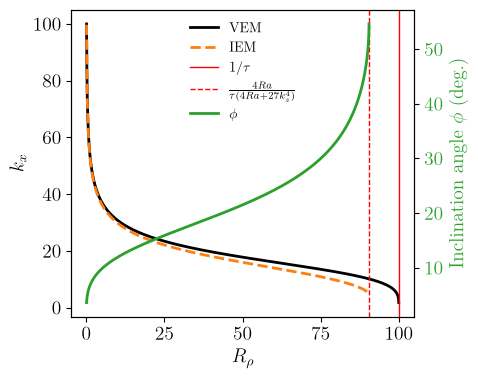

In [38]:
Ra = 1e5
tau = 0.01

fig, ax1 = plt.subplots(figsize=(5,4))

# ----- Left axis: kx -----
Rrho = np.arange(0.1,100,0.01)
kx_VEM_via_Rrho = VEM_kx(Ra=Ra,tau=tau,Rrho=Rrho)
ax1.plot(Rrho, kx_VEM_via_Rrho, lw=2, color='k', linestyle='-', label='VEM',zorder=0)

lim_Rrho_iem = 4*Ra/(tau*(4*Ra+27*kz**4))
print(f"Lim of Rrho_iem = {lim_Rrho_iem}")
Rrho_IEM = np.arange(0.1,90,0.01)
Rrho_IEM = np.concatenate([Rrho_IEM, np.arange(90., lim_Rrho_iem, 0.001)])
# kx_IEM_via_Rrho = IEM_kx_cardano(Rrho=Rrho_IEM)
kx_IEM_via_Rrho = np.zeros(len(Rrho_IEM))
for i, Rrho in enumerate(Rrho_IEM):
    kx_IEM_via_Rrho[i] = IEM_kx_cardano(Ra=Ra,tau=tau,Rrho=Rrho)
print(f"Lim of kx_iem = {kx_IEM_via_Rrho[-1]}")

ax1.plot(Rrho_IEM, kx_IEM_via_Rrho, lw=2, color='tab:orange', linestyle='--', label='IEM',zorder=1)
ax1.set_xlabel(r'$R_\rho$')
ax1.set_ylabel(r'$k_x$', color='black')
# ax1.set_yscale('log')
ax1.tick_params(axis='y')
ax1.axvline(x=1/tau, color='r', lw=1, label=r'$1/\tau$', zorder=2)
ax1.axvline(x=4.*Ra/(tau*(4*Ra+27*kz**4)), linestyle='--', color='r', lw=1, label=r'$\frac{4Ra}{\tau(4Ra+27k_z^4)}$', zorder=2)


# ----- Right axis: inclination angle -----
ax2 = ax1.twinx()

angle = np.arctan(kz/kx_IEM_via_Rrho) * 180/np.pi
ax2.plot(Rrho_IEM, angle, lw=2, color='tab:green', linestyle='-', label=r'$\phi$',zorder=1)

ax2.set_ylabel(r'Inclination angle $\phi$ (deg.)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# ----- Combined legend -----
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', frameon=False, fontsize=10)


plt.tight_layout()
plt.savefig('supp_Fig1c.png',dpi=300, bbox_inches='tight')
plt.show()

## Fig. 1c: Check $k_x$ for varying Ra

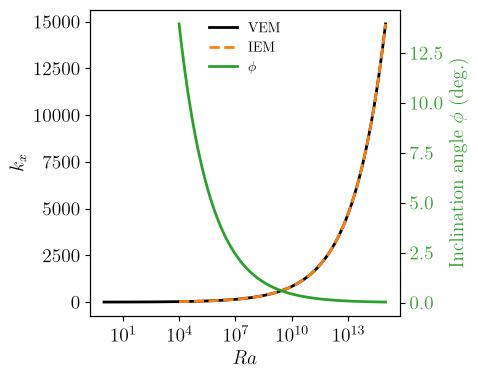

In [40]:
fig, ax1 = plt.subplots(figsize=(5,4))

# ----- Left axis: kx -----
Ra = np.logspace(0,15,100)
# print(Ra)
kx_VEM_via_Ra = VEM_kx(Ra=Ra,tau=0.01,Rrho=2.0)
# print(kx_VEM_via_Ra)
ax1.plot(Ra, kx_VEM_via_Ra, lw=2, color='k', linestyle='-', label='VEM',zorder=0)

lim_Ra_iem =[]
# print(lim_Ra_iem)
Ra_IEM = np.logspace(4,15,100)

# Ra_IEM = np.concatenate([Ra_IEM, [lim_Ra_iem]])
kx_IEM_via_Ra = np.zeros(len(Ra_IEM))
for i, Ra in enumerate(Ra_IEM):
    kx_IEM_via_Ra[i] = IEM_kx_cardano(Ra=Ra,tau=0.01,Rrho=2.0)
ax1.plot(Ra_IEM, kx_IEM_via_Ra, lw=2, color='tab:orange', linestyle='--', label='IEM',zorder=1)

ax1.set_xlabel(r'$Ra$')
ax1.set_ylabel(r'$k_x$', color='black')
# ax1.set_yscale('log')
ax1.tick_params(axis='y')
ax1.set_xscale('log')
# ----- Right axis: inclination angle -----
ax2 = ax1.twinx()

angle = np.arctan(kz/kx_IEM_via_Ra) * 180/np.pi
ax2.plot(Ra_IEM, angle, lw=2, color='tab:green', linestyle='-', label=r'$\phi$',zorder=2)

ax2.set_ylabel(r'Inclination angle $\phi$ (deg.)', color='tab:green')
ax2.tick_params(axis='y', labelcolor='tab:green')

# ----- Combined legend -----
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper center', frameon=False, fontsize=10)

plt.tight_layout()
plt.savefig('supp_Fig1d.png', dpi=300, bbox_inches='tight')
plt.show()